<a href="https://colab.research.google.com/github/160423737030-lab/Codveda-Machine-Learning-Internship/blob/main/level3_task1_Randomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (178, 14)
Target Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Missing Values: 0

Baseline Random Forest Test Accuracy: 1.0000

Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Best Cross-Validation Accuracy: 0.9862

Tuned Random Forest Test Accuracy: 1.0000

Confusion Matrix:
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:
               precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



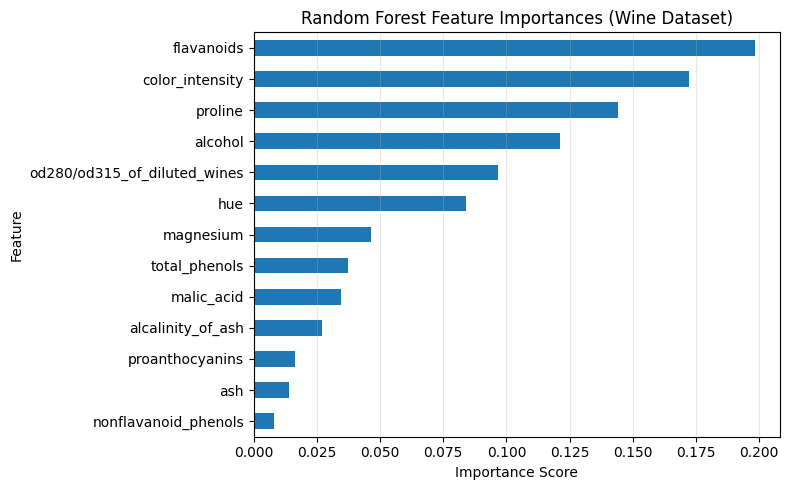

In [3]:
# ==========================================
# Codveda Technologies - Machine Learning Internship
# Level 3 (Advanced) - Task 1: Random Forest Classifier
# Intern: MD JUNAID KHAN
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Load Dataset (Wine Classification Dataset)
wine = load_wine(as_frame=True)
df = wine.frame
X = wine.data
y = wine.target
class_names = list(wine.target_names)

print("Dataset Shape:", df.shape)
print("Target Classes:", class_names)
print("Missing Values:", df.isnull().sum().sum())

# 2. Train-Test Split (80% Train, 20% Test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Baseline Random Forest Classifier
rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train, y_train)
base_pred = rf_base.predict(X_test)
print(f"\nBaseline Random Forest Test Accuracy: {accuracy_score(y_test, base_pred):.4f}")

# 4. Hyperparameter Tuning using GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 4, 6, 8],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
print("\nBest Hyperparameters:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

# 5. Evaluate Tuned Random Forest on Test Set
y_pred = best_rf.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print(f"\nTuned Random Forest Test Accuracy: {test_acc:.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=class_names))

# 6. Feature Importance Visualization
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.title('Random Forest Feature Importances (Wine Dataset)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.grid(True, axis='x', alpha=0.3)
plt.show()